# Notebook 2: Comparing Mean and Osculating Orbital Elements

We observe the time evolution of the mean orbital elements provided in a Two-Line Element (TLE) and the osculating elements at 1-hour intervals at the same epochs, which are the SGP4-propagated mean elements with secular evolution and short- as well as long-period periodic variational corrections appended. This helps better visualise what the mean orbital elements capture, compared to the osculating elements captured by the instantaneous satellite states that account for perturbations.

In this notebook, I will focus on comparing the mean and osculating orbital elements specifically for LAGEOS-1, a Medium Earth Orbit (MEO) satellite, where the TLEs were sourced from [Space-Track](www.space-track.org) for the year 2025. Hence, the annual evolution for the year 2025 will be investigated.

### Extracting 2025 TLE Elements for LAGEOS-1

I begin by first extracting the TLE elements for LAGEOS-1 for every TLE scraped between January 1st and December 31st 2025. The TLEs are first sorted by epoch, removing duplicates and retaining the TLE with the latest creation date for more precise ephemeris.

In [8]:
# General Imports:
import os
import sys
import subprocess
import numpy as np
import pandas as pd
from pathlib import Path
from sgp4.model import Satrec, WGS72

# Establish Java path to remove error:
os.environ["JAVA_HOME"] = str(Path(sys.prefix) / "Library" / "jre")

# Brent Imports:
from brent.propagators.analytical.tle import (
    TLEPropagator,
    TLEPropagatorMethod
)
from brent import Constants

# Establish Java path to remove error:
os.environ["JAVA_HOME"] = str(Path(sys.prefix) / "Library" / "jre")

# Repo paths + frame:
data_path = Path.cwd().resolve().parent / "data"
download_path = Path.cwd().resolve().parent / "download"

In [9]:
# TLE paths for LAGEOS-1:
tle_path = download_path / "tle" / "8820.json"
df = pd.read_json(tle_path)

df.columns

Index(['CCSDS_OMM_VERS', 'COMMENT', 'CREATION_DATE', 'ORIGINATOR',
       'OBJECT_NAME', 'OBJECT_ID', 'CENTER_NAME', 'REF_FRAME', 'TIME_SYSTEM',
       'MEAN_ELEMENT_THEORY', 'EPOCH', 'MEAN_MOTION', 'ECCENTRICITY',
       'INCLINATION', 'RA_OF_ASC_NODE', 'ARG_OF_PERICENTER', 'MEAN_ANOMALY',
       'EPHEMERIS_TYPE', 'CLASSIFICATION_TYPE', 'NORAD_CAT_ID',
       'ELEMENT_SET_NO', 'REV_AT_EPOCH', 'BSTAR', 'MEAN_MOTION_DOT',
       'MEAN_MOTION_DDOT', 'SEMIMAJOR_AXIS', 'PERIOD', 'APOAPSIS', 'PERIAPSIS',
       'OBJECT_TYPE', 'RCS_SIZE', 'COUNTRY_CODE', 'LAUNCH_DATE', 'SITE',
       'DECAY_DATE', 'FILE', 'GP_ID', 'TLE_LINE0', 'TLE_LINE1', 'TLE_LINE2'],
      dtype='str')

In [10]:
# Sort TLEs + remove duplicate epochs:
df["EPOCH"] = pd.to_datetime(df["EPOCH"], utc=True).dt.tz_localize(None)
df["CREATION_DATE"] = pd.to_datetime(df["CREATION_DATE"], utc=True)
df = df[(df["EPOCH"] >= "2025-01-01") & (df["EPOCH"] < "2026-01-01")]  # only 2025
df = df.sort_values(["EPOCH", "CREATION_DATE"])
df = df.drop_duplicates("EPOCH", keep="last")  # drop stalest TLEs at duplicate epochs
df = df.reset_index(drop=True)  # TLEs indexed in chronological order

# Extract mean elements from the TLEs:
e = df["ECCENTRICITY"].to_numpy(dtype=float)
i = df["INCLINATION"].to_numpy(dtype=float)
raan = df["RA_OF_ASC_NODE"].to_numpy(dtype=float)
omega = df["ARG_OF_PERICENTER"].to_numpy(dtype=float)
M = np.deg2rad(df["MEAN_ANOMALY"].to_numpy(dtype=float))

df.head(5)

,CCSDS_OMM_VERS,COMMENT,CREATION_DATE,ORIGINATOR,OBJECT_NAME,OBJECT_ID,CENTER_NAME,REF_FRAME,TIME_SYSTEM,MEAN_ELEMENT_THEORY,...,RCS_SIZE,COUNTRY_CODE,LAUNCH_DATE,SITE,DECAY_DATE,FILE,GP_ID,TLE_LINE0,TLE_LINE1,TLE_LINE2
0,3.0,GENERATED VIA SPACE-TRACK.ORG API,2025-01-01 23:41:24+00:00,18 SPCS,LAGEOS 1,1976-039A,EARTH,TEME,UTC,SGP4,...,MEDIUM,US,1976-05-04,AFWTR,NaN,4598149,277043280,0 LAGEOS 1,1 08820U 76039A 25001.13974220 .00000019 0...,2 08820 109.8523 357.0926 0044138 55.8219 315...
1,3.0,GENERATED VIA SPACE-TRACK.ORG API,2025-01-02 19:02:11+00:00,18 SPCS,LAGEOS 1,1976-039A,EARTH,TEME,UTC,SGP4,...,MEDIUM,US,1976-05-04,AFWTR,NaN,4598496,277110144,0 LAGEOS 1,1 08820U 76039A 25002.45726355 .00000019 0...,2 08820 109.8531 357.5433 0044100 55.5246 105...
2,3.0,GENERATED VIA SPACE-TRACK.ORG API,2025-01-07 18:07:06+00:00,18 SPCS,LAGEOS 1,1976-039A,EARTH,TEME,UTC,SGP4,...,MEDIUM,US,1976-05-04,AFWTR,NaN,4603301,277521054,0 LAGEOS 1,1 08820U 76039A 25007.23315350 .00000025 0...,2 08820 109.8536 359.1775 0044183 54.4700 285...
3,3.0,GENERATED VIA SPACE-TRACK.ORG API,2025-01-08 20:49:28+00:00,18 SPCS,LAGEOS 1,1976-039A,EARTH,TEME,UTC,SGP4,...,MEDIUM,US,1976-05-04,AFWTR,NaN,4604166,277598650,0 LAGEOS 1,1 08820U 76039A 25008.55898025 .00000023 0...,2 08820 109.8539 359.6312 0044151 54.1770 94...
4,3.0,GENERATED VIA SPACE-TRACK.ORG API,2025-01-09 20:58:34+00:00,18 SPCS,LAGEOS 1,1976-039A,EARTH,TEME,UTC,SGP4,...,MEDIUM,US,1976-05-04,AFWTR,NaN,4604746,277699556,0 LAGEOS 1,1 8820U 76039A 25009.26847366 .00000021 0...,2 8820 109.8542 359.8740 0044129 54.0129 285...


## 1. Mean Elements:

The idea for the mean elements is to extract the raw TLE elements, add the secular, long-period and short-period periodic updates, and then plot the corrected elements over time. This is akin to almost manually performing SGP4 via the theory provided in Hoots et al. (2004). These will be then compared to the classical osculating elements i.e., the instantaneous Keplerian orbital elements yielded by SGP4 from the calculated ($\vec{r}, \vec{v}$) quantities.

The TLE elements at each epoch will be obtained and then updated at regular 1-hour time intervals, until the next TLE that is available.
 
### Kozai-to-Brouwer Convention Recovery at TLE Epoch

Having extracted the TLE $e, i, \Omega, \omega$, and $M$ elements, in accordance with Hoots et al. (2004) specifically Appendix B (Initialisation), we will initialise the Brouwer semi-major axis $a_0''$.

The next thing is to define a function that extracts the initial raw TLE elements, such that we will take these TLEs, update them using the secular effects and periodic corrections provided in Hoots et al. (2024), and then continue performing this update until the next TLE is available.

In [11]:
# Extract TLE elements, initialise SGP4 model to store perturbation coefficients:


def initialise_sgp4(record):
    return Satrec.twoline2rv(
        record["TLE_LINE1"],
        record["TLE_LINE2"],
        WGS72
    )

### Secular Updates for Earth Zonal Gravity ($M, \omega, \Omega$)

Earth's zonal gravitational harmonics cause secular changes in mean anomaly, RAAN, and argument of periapsis. Following Hoots et al. (2004), Appendix B:

$$
M(t) = M_0 + (n_0'' + \dot{M}_{z})\Delta t
$$

$$
\omega(t) = \omega_0 + \dot{\omega}_{z}\Delta t
$$

$$
\Omega(t) = \Omega_0 + \dot{\Omega}_{z}\Delta t
+ C_{\Omega}(\Delta t)^2
$$

where $\Delta t=t-t_0$ is the elapsed time since the TLE epoch in minutes. $\dot{M}_{z}$, $\dot{\omega}_{z}$ and $\dot{\Omega}_{z}$ are calculated during SGP4 initialisation, where the Python implementation of the above terms are:

- `sat.mdot` $\rightarrow n_0''+\dot{M}_{z}$
- `sat.argpdot` $\rightarrow \dot{\omega}_{z}$
- `sat.nodedot` $\rightarrow \dot{\Omega}_{z}$
- `sat.nodecf` $\rightarrow C_{\Omega}$

In [12]:
def secular_earth_zonal(sat, dt):
    return {
        "e": sat.ecco,  # unchanged
        "i": sat.inclo,  # unchanged
        "raan": sat.nodeo + sat.nodedot*dt + sat.nodecf*dt**2,
        "omega": sat.argpo + sat.argpdot*dt,
        "M": sat.mo + sat.mdot*dt,
        "n": sat.no_unkozai  # brouwer-convention
    }

### Secular Updates for Lunisolar Gravity Effects ($e, i, \Omega, \omega, M$)

Lunar and solar gravitational perturbations introduce additional secular rates of change:

$$
\dot e_{LS} = \dot e_{\mathrm{Moon}}+\dot e_{\mathrm{Sun}}
$$

whereby the following elements are updated such that

$$
e(t)=e_{\mathrm{previous}}+\dot e_{LS}\Delta t
$$

$$
i(t)=i_{\mathrm{previous}}+\dot i_{LS}\Delta t
$$

$$
\Omega(t)=\Omega_{\mathrm{previous}}+\dot\Omega_{LS}\Delta t
$$

$$
\omega(t)=\omega_{\mathrm{previous}}+\dot\omega_{LS}\Delta t
$$

$$
M(t)=M_{\mathrm{previous}}+\dot M_{LS}\Delta t
$$

where "previous" denotes the elements after the Earth-zonal secular update. The lunar/solar secular rates are calculated during SGP4 initialisation (Hoots et al., 2024) and are stored in Python as:
- `dedt` $\rightarrow \dot e_{LS}$
- `didt` $\rightarrow \dot i_{LS}$
- `dnodt` $\rightarrow \dot \Omega_{LS}$
- `domdt` $\rightarrow \dot \omega_{LS}$
- `dmdt` $\rightarrow \dot M_{LS}$

These rates are applied only when the satellite uses SGP4's deep-space branch.

In [13]:
def secular_lunisolar(sat, state, dt):
    s = state.copy()
    if sat.method == "d":  # deep space setting
        s["e"] += sat.dedt * dt
        s["i"] += sat.didt * dt
        s["raan"] += sat.dnodt * dt
        s["omega"] += sat.domdt * dt
        s["M"] += sat.dmdt * dt

    return s

### Secular Updates for Resonance Effects of Earth Gravity

SGP4 includes additional perturbation terms for satellites in resonance with Earth's rotation, where Hoots et al. (2004) considers one-day and half-day resonance. LAGEOS-1 does not satisfy either resonance condition, where no corrections are therefore applied in this case. For completeness, `secular_resonance()` checks `sat.irez`, where `0` indicates no resonance.

In [14]:
def secular_resonance(sat, state):
    if sat.irez != 0:
        raise NotImplementedError("Resonance integration is not implemented.")

    return state.copy()

### Secular Updates for Remaining Atmospheric Drag ($a, e$)

Atmospheric drag introduces secular changes to the semimajor axis, eccentricity and mean longitude. Following Hoots et al. (2004), Appendix B, Update Section 4:

$$
e=e_0-B^*C_4\Delta t
-B^*C_5(\sin M-\sin M_0)
$$

$$
a=\left(\frac{k_e}{n}\right)^{2/3}
\left[1-C_1\Delta t-D_2\Delta t^2
-D_3\Delta t^3-D_4\Delta t^4\right]^2
$$

For deep-space satellites, the higher-order drag terms and the $C_5$ term are omitted (Hoots et al., 2004) such that the updates are simplified to:

$$
e_{\mathrm{updated}} =e_{\mathrm{secular}}-B^*C_4\Delta t \; \; \; \; \; (1)
$$

$$
a_{\mathrm{updated}} =\left(\frac{k_e}{n_{\mathrm{secular}}}\right)^{2/3}(1-C_1\Delta t)^2 \; \; \; \; \; (2)
$$

$$
n_{\mathrm{updated}}=\frac{k_e}{a_{\mathrm{updated}}^{3/2}} \; \; \; \; \; (3)
$$

including a quadratic drag contribution to the mean longitude:

$$
\Delta I_L=\frac{3}{2}n_0''C_1\Delta t^2
$$

where:

- $B^* = $ TLE drag parameter.
- $C_1=B^*C_2$.
- $C_4 = $ atmospheric-drag coefficient.
- $\Delta t = $ elapsed time [minutes].

The coefficients are calculated during SGP4 initialisation and are called, accordingly.


In [15]:
def secular_remaining_drag(sat, state, dt):
    if sat.isimp != 1:
        raise NotImplementedError("Simplified drag branch for deep-space is in use.")

    s = state.copy()
    # Atmospheric drag factors
    consta = 1.0 - sat.cc1 * dt  # from (1)
    conste = sat.bstar * sat.cc4 * dt  # from (2)
    consti_l = sat.t2cof * dt**2  # from (3)

    # Updated mean semimajor axis (Earth radii)
    s["a_er"] = (sat.xke / s["n"])**(2/3) * consta**2  # (2)
    # Updated mean motion
    s["n"] = sat.xke / s["a_er"]**1.5  # (3)
    # Updated eccentricity and mean anomaly
    s["e"] -= conste
    s["M"] += sat.no_unkozai * consti_l

    # Normalise angular elements
    xlm = (s["M"] + s["omega"] + s["raan"]) % (2*np.pi)
    s["raan"] %= 2*np.pi
    s["omega"] %= 2*np.pi
    s["M"] = (xlm - s["omega"] - s["raan"]) % (2*np.pi)

    return s

### Long-Period Periodic Update for Lunisolar Gravity Effects ($e, i, \Omega, \omega, M$)

The long-period lunar and solar corrections depend on the orbital positions of the perturbing bodies. For each perturbing body $X$, representing either the Moon or Sun $\{L, S\}$:

$$
M_X(t)=M_{X,0}+n_X\Delta t
$$

where the true anomaly is approximated (Hoots et al., 2004), such that

$$
\theta_X=M_X+2e_X\sin M_X \; \; \; \; \; (4)
$$

Lunar and solar perturbation coefficients are calculated during initialisation in accordance to Hoots et al. (2004) Appendix A.E, to obtain:

$$
\delta e_{LS},\quad
\delta i_{LS},\quad
\delta\Omega_{LS},\quad
\delta\omega_{LS},\quad
\delta M_{LS}
$$

The updated eccentricity and inclination, where $LP$ denotes long-period,  is therefore

$$
e_{\mathrm{LP}}=e_{\mathrm{secular}}+\delta e_{LS}
$$

$$
i_{\mathrm{LP}}=i_{\mathrm{secular}}+\delta i_{LS}
$$

In [16]:
l_i = np.deg2rad(df["INCLINATION"]).min()
print(rf"LAGEOS-1 Inclination [rad]: {l_i:.2f}")

LAGEOS-1 Inclination [rad]: 1.92


For $i > 0.2$ rad, the update implementation follows:

$$\Omega = \Omega + \delta\Omega_{\mathrm{LS}} / \sin i \; \; \; \; \; (5)$$

$$\omega = \omega + (\delta\omega_{\mathrm{LS}} + \cos i \, \delta\Omega_{\mathrm{LS}}) - \delta\Omega_{\mathrm{LS}} \cos i / \sin i \; \; \; \; \; (6)$$

$$M = M + \delta M_{\mathrm{LS}} \; \; \; \; \; (7)$$

where the above equations are corresponding to the long-period corrections described in Hoots et al. (2004) Appendix A.E. The below coding implementation simplifies the equations in the corresponding paper by grouping coefficients and referring to the SGP4 GitHub repository for guidance.

In [17]:
# Intermediate helper functions 

def f2_f3(z, ecc):
    f = z + 2 * ecc * np.sin(z)  #  (4)
    # Auxiliary periodic function
    f2 = 0.5 * np.sin(f)**2 - 0.25
    f3 = -0.5 * np.sin(f) * np.cos(f)

    return f2, f3, np.sin(f)

# Long-period periodic lunisolar correction:


def long_period_lunisolar(sat, state, dt):
    s = state.copy()
    if sat.method != "d":  # not deep space
        return s

    # Solar + lunar auxiliary helper functions
    f2s, f3s, sins = f2_f3(sat.zmos + 1.19459e-5 * dt, 0.01675)
    f2m, f3m, sinm = f2_f3(sat.zmol + 1.5835218e-4 * dt, 0.05490)
    # Eccentricity correction
    de = (sat.se2*f2s + sat.se3*f3s + sat.ee2*f2m + sat.e3*f3m - sat.peo)
    # Inclination correction
    di = (sat.si2*f2s + sat.si3*f3s + sat.xi2*f2m + sat.xi3*f3m - sat.pinco)
    # Mean anomaly correction
    dM = (sat.sl2*f2s + sat.sl3*f3s + sat.sl4*sins + sat.xl2*f2m + sat.xl3*f3m + sat.xl4*sinm
        - sat.plo)
    # Periapsis correction
    domega = (sat.sgh2*f2s + sat.sgh3*f3s + sat.sgh4*sins + sat.xgh2*f2m + sat.xgh3*f3m
              + sat.xgh4*sinm - sat.pgho)
    # Nodal correction
    dnode = (sat.sh2*f2s + sat.sh3*f3s + sat.xh2*f2m + sat.xh3*f3m - sat.pho)
    # Apply eccentricity and inclination corrections
    s["e"] += de
    s["i"] += di

    # Direct periodic correction branch for LAGEOS-1
    if not (0.2 <= s["i"] <= np.pi):
        raise NotImplementedError(
            "This inclination requires the Lyddane branch."
        )

    d_raan = dnode / np.sin(s["i"])  # (5)
    s["raan"] += d_raan  # (5)
    s["omega"] += domega - np.cos(s["i"]) * d_raan  # (6)
    s["M"] += dM  # (7)

    return s

### Perform Secular and Long-Period Periodic Update

In [18]:
# 15-minute timestamps for one week
dates = pd.date_range("2025-01-01", "2025-01-07", freq="15min", inclusive="left")

# Find latest preceding TLE
tle_epochs = df["EPOCH"].to_numpy(dtype="datetime64[ns]")
selected_idx = np.searchsorted(tle_epochs, dates.to_numpy(dtype="datetime64[ns]"), side="right") - 1

In [19]:
# Ensure satellites are not repeated:
sat_cache = {}
rows = []

for date, idx in zip(dates, selected_idx):
    if idx < 0:
        continue
    idx = int(idx)
    record = df.iloc[idx]
    if idx not in sat_cache:
        sat_cache[idx] = initialise_sgp4(record)  # get TLE elements
    sat = sat_cache[idx]

    # minutes since selected TLE epoch:
    dt = (date - record["EPOCH"]).total_seconds()/60

    # Secular perturbations:
    zonal = secular_earth_zonal(sat, dt)
    secular = secular_lunisolar(sat, zonal, dt)
    secular = secular_resonance(sat, secular)
    mean = secular_remaining_drag(sat, secular, dt)

    # Long-period lunisolar perturbations:
    lunisolar = long_period_lunisolar(sat, mean, dt)

    # Save updated orbital elements:
    rows.append({
        "epoch_utc": date,
        "tle_epoch_utc": record["EPOCH"],
        "a_mean_km": mean["a_er"] * sat.radiusearthkm,
        "e_mean": mean["e"],
        "i_mean_deg": np.degrees(mean["i"]),
        "raan_mean_deg": np.degrees(mean["raan"]) % 360,
        "omega_mean_deg": np.degrees(mean["omega"]) % 360,
        "M_mean_deg": np.degrees(mean["M"]) % 360,
        "e_lunisolar": lunisolar["e"],
        "i_lunisolar_deg": np.degrees(lunisolar["i"]),
        "raan_lunisolar_deg": np.degrees(lunisolar["raan"]) % 360,
        "omega_lunisolar_deg": np.degrees(lunisolar["omega"]) % 360,
        "M_lunisolar_deg": np.degrees(lunisolar["M"]) % 360,
    })

mean_stages = pd.DataFrame(rows)
mean_path = data_path / "mean-elements"
mean_path.mkdir(parents=True, exist_ok=True)
mean_stages.to_csv(mean_path / "lageos1_mean_2025.csv", index=False)

print("Number of mean element sets:", len(rows))

Number of mean element sets: 562


## 2. Osculating Elements:

### Deriving from $(\vec{r}_{\text{TLE}}, \vec{v}_{\text{TLE}})$ 

Loading the pre-derived positional and velocity vectors $\vec{r}_{\text{TLE}}$ and $\vec{v}_{\text{TLE}}$ calculated and exported into CSV files in a [previous noteboook](01_tle_sp3_residuals.ipynb), we can now plug these into equations for deriving osculating orbital elements, where:

$$
\vec{r}_{\mathrm{TLE}} =
\begin{bmatrix}x\\y\\z\end{bmatrix},
\qquad
\vec{v}_{\mathrm{TLE}} =
\begin{bmatrix}v_x\\v_y\\v_z\end{bmatrix}.
$$


The classical osculating orbital elements are recovered from these vectors using the two-body relations, where all angular elements are in degrees. Using the vis-viva equation, the osculating semi-major axis can be obtained via

$$
a_{\mathrm{osc}} =
\frac{1}{
\frac{2}{r}-\frac{v^2}{\mu}
} \; \; \; \; \; (1)
$$

The eccentricity vector is

$$
\vec{e} =
\frac{\vec{v}_{\mathrm{TLE}}\times\vec{h}}{\mu}
-\frac{\vec{r}_{\mathrm{TLE}}}{r}
$$

Thus, taking the magnitude yields the osculating eccentricity such that

$$
e_{\mathrm{osc}}=\|\vec{e}\| \; \; \; \; \; (2)
$$

The osculating inclination can be found via

$$
i_{\mathrm{osc}} =
\cos^{-1}\left(\frac{h_z}{h}\right) \; \; \; \; \; (3)
$$

The right ascension of the ascending node (RAAN) is obtained through

$$
\Omega_{\mathrm{osc}} =
\begin{cases}
\cos^{-1}\left(\frac{N_x}{N}\right), & N_y\geq0,\; \; \; \; \; (4)\\
2\pi-\cos^{-1}\left(\frac{N_x}{N}\right), & N_y<0.
\end{cases}
$$

The argument of periapsis can be calculated such that
$$
\omega_{\mathrm{osc}} =
\begin{cases}
\cos^{-1}\left(\frac{\mathbf N\cdot\mathbf e}{Ne}\right), & e_z\geq0, \; \; \; \; \; (5)\\
2\pi-\cos^{-1}\left(\frac{\mathbf N\cdot\mathbf e}{Ne}\right),
& e_z<0.
\end{cases}
$$

Finally, the true anomaly of a satellite is obtained using
$$
\theta_{\mathrm{osc}} =
\begin{cases}
\cos^{-1}\left(
\frac{\mathbf e\cdot\mathbf r_{\mathrm{TLE}}}{er}
\right), & \mathbf r_{\mathrm{TLE}}\cdot\mathbf v_{\mathrm{TLE}}\geq0, \; \; \; \; \; (6)\\
2\pi-\cos^{-1}\left(
\frac{\mathbf e\cdot\mathbf r_{\mathrm{TLE}}}{er}
\right), & \mathbf r_{\mathrm{TLE}}\cdot\mathbf v_{\mathrm{TLE}}<0.
\end{cases}
$$

In [20]:
# Load LAGEOS-1's historical TLEs
tle = TLEPropagator.load(path=str(tle_path), method=TLEPropagatorMethod.FORWARD)
comparison_dates = pd.DatetimeIndex(mean_stages["epoch_utc"])  # same as mean elements

# Propagate SGP4 to each 15-minute timestamp in GCRF:
states = [np.asarray(tle._propagate(date.to_pydatetime(), Constants.DEFAULT_ECI), dtype=float) for date in comparison_dates]
tle_states = pd.DataFrame(states, columns=["x_m", "y_m", "z_m", "vx_m_s", "vy_m_s", "vz_m_s"])
tle_states.insert(0, "epoch_utc", comparison_dates)
print("Number of propagated states:", len(tle_states))

tle_states.head(5)


Number of propagated states: 562


,epoch_utc,x_m,y_m,z_m,vx_m_s,vy_m_s,vz_m_s
0,2025-01-01 03:30:00,1.092702e+07,-2.403449e+06,4.920487e+06,-2559.827034,-1608.381202,4858.722145
1,2025-01-01 03:45:00,7.737792e+06,-3.599103e+06,8.735938e+06,-4422.986732,-1009.133622,3494.121667
2,2025-01-01 04:00:00,3.198323e+06,-4.166676e+06,1.102555e+07,-5515.251434,-233.563153,1518.785178
3,2025-01-01 04:15:00,-1.899137e+06,-4.007669e+06,1.139092e+07,-5645.003829,581.314322,-717.804650
4,2025-01-01 04:30:00,-6.666857e+06,-3.151641e+06,9.773546e+06,-4794.552322,1292.454806,-2821.895698


In [21]:
# Get instataneous r and v + useful vectors:
r = np.sqrt(tle_states['x_m']**2 + tle_states['y_m']**2 + tle_states['z_m']**2).to_numpy()
v = np.sqrt(tle_states['vx_m_s']**2 + tle_states['vy_m_s']**2 + tle_states['vz_m_s']**2).to_numpy()
r_vec = tle_states[['x_m', 'y_m', 'z_m']].to_numpy()
v_vec = tle_states[['vx_m_s', 'vy_m_s', 'vz_m_s']].to_numpy()

mu = (6.6743*10**-11)*(5.972*10**24)  # mu = GM
h = np.cross(r_vec, v_vec)  # momentum vector
h_mag = np.linalg.norm(h, axis=1)
z_hat = np.array([0, 0, 1])
N = np.cross(z_hat, h)  # nodal vector (direction of AN)
N_mag = np.linalg.norm(N, axis=1)

# Semi-major axis:
a = 1/((2/r)-(v**2/mu))  # using (1)

# Eccentricity:
e_vec = np.cross(v_vec, h)/mu - r_vec/r[:, None]
e = np.linalg.norm(e_vec, axis=1)  # using (2)

# Inclination:
i = np.degrees(np.arccos(np.clip(h[:, 2]/h_mag, -1, 1)))  # using (3)

# RAAN:
raan = np.degrees(np.arctan2(N[:, 1], N[:, 0]))%360  # using (4)

# Argument of periapsis:
omega = np.degrees(np.arccos(np.clip(np.sum(N*e_vec, axis=1) / (N_mag*e), -1, 1)))
omega = np.where(e_vec[:, 2] < 0, 360 - omega, omega)  # using (5)

# True anomaly:
theta = np.degrees(np.arccos(np.clip(np.sum(e_vec*r_vec, axis=1)/(e*r), -1, 1)))
theta = np.where(np.sum(r_vec*v_vec, axis=1) < 0, 360 - theta, theta)  # using (6)

# Saving osculating orbital elements to CSV:
osc_elements = pd.DataFrame({
    "epoch_utc": tle_states["epoch_utc"],
    "a_osc_km": a*0.001,
    "e_osc": e,
    "i_osc_deg": i,
    "raan_osc_deg": raan,
    "omega_osc_deg": omega,
    "theta_osc_deg": theta
})

osc_path = data_path / "osc-elements"
osc_path.mkdir(parents=True, exist_ok=True)
osc_elements.to_csv(osc_path / "lageos1_osc_2025.csv", index=False)

print("Number of osculating element sets:", len(osc_elements))


Number of osculating element sets: 562


## 3. Comparison:

### Plotting Mean and Osculating Orbit Elements over Time

In [28]:
# Running script from Jupyter notebook + bypassing kernel crash:
conda_path = Path(sys.prefix)

# Include Conda's DLL directories
env = os.environ.copy()
env["PATH"] = os.pathsep.join([
    str(conda_path),
    str(conda_path / "Library" / "bin"),
    str(conda_path / "Library" / "usr" / "bin"),
    str(conda_path / "Scripts"),
    env.get("PATH", "")
])

# Run plotting script in a separate process
subprocess.run([sys.executable, "plot_osc_mean_elements.py"], env=env, check=True)

CompletedProcess(args=['c:\\Users\\lette\\anaconda3\\envs\\brent\\python.exe', 'plot_osc_mean_elements.py'], returncode=0)

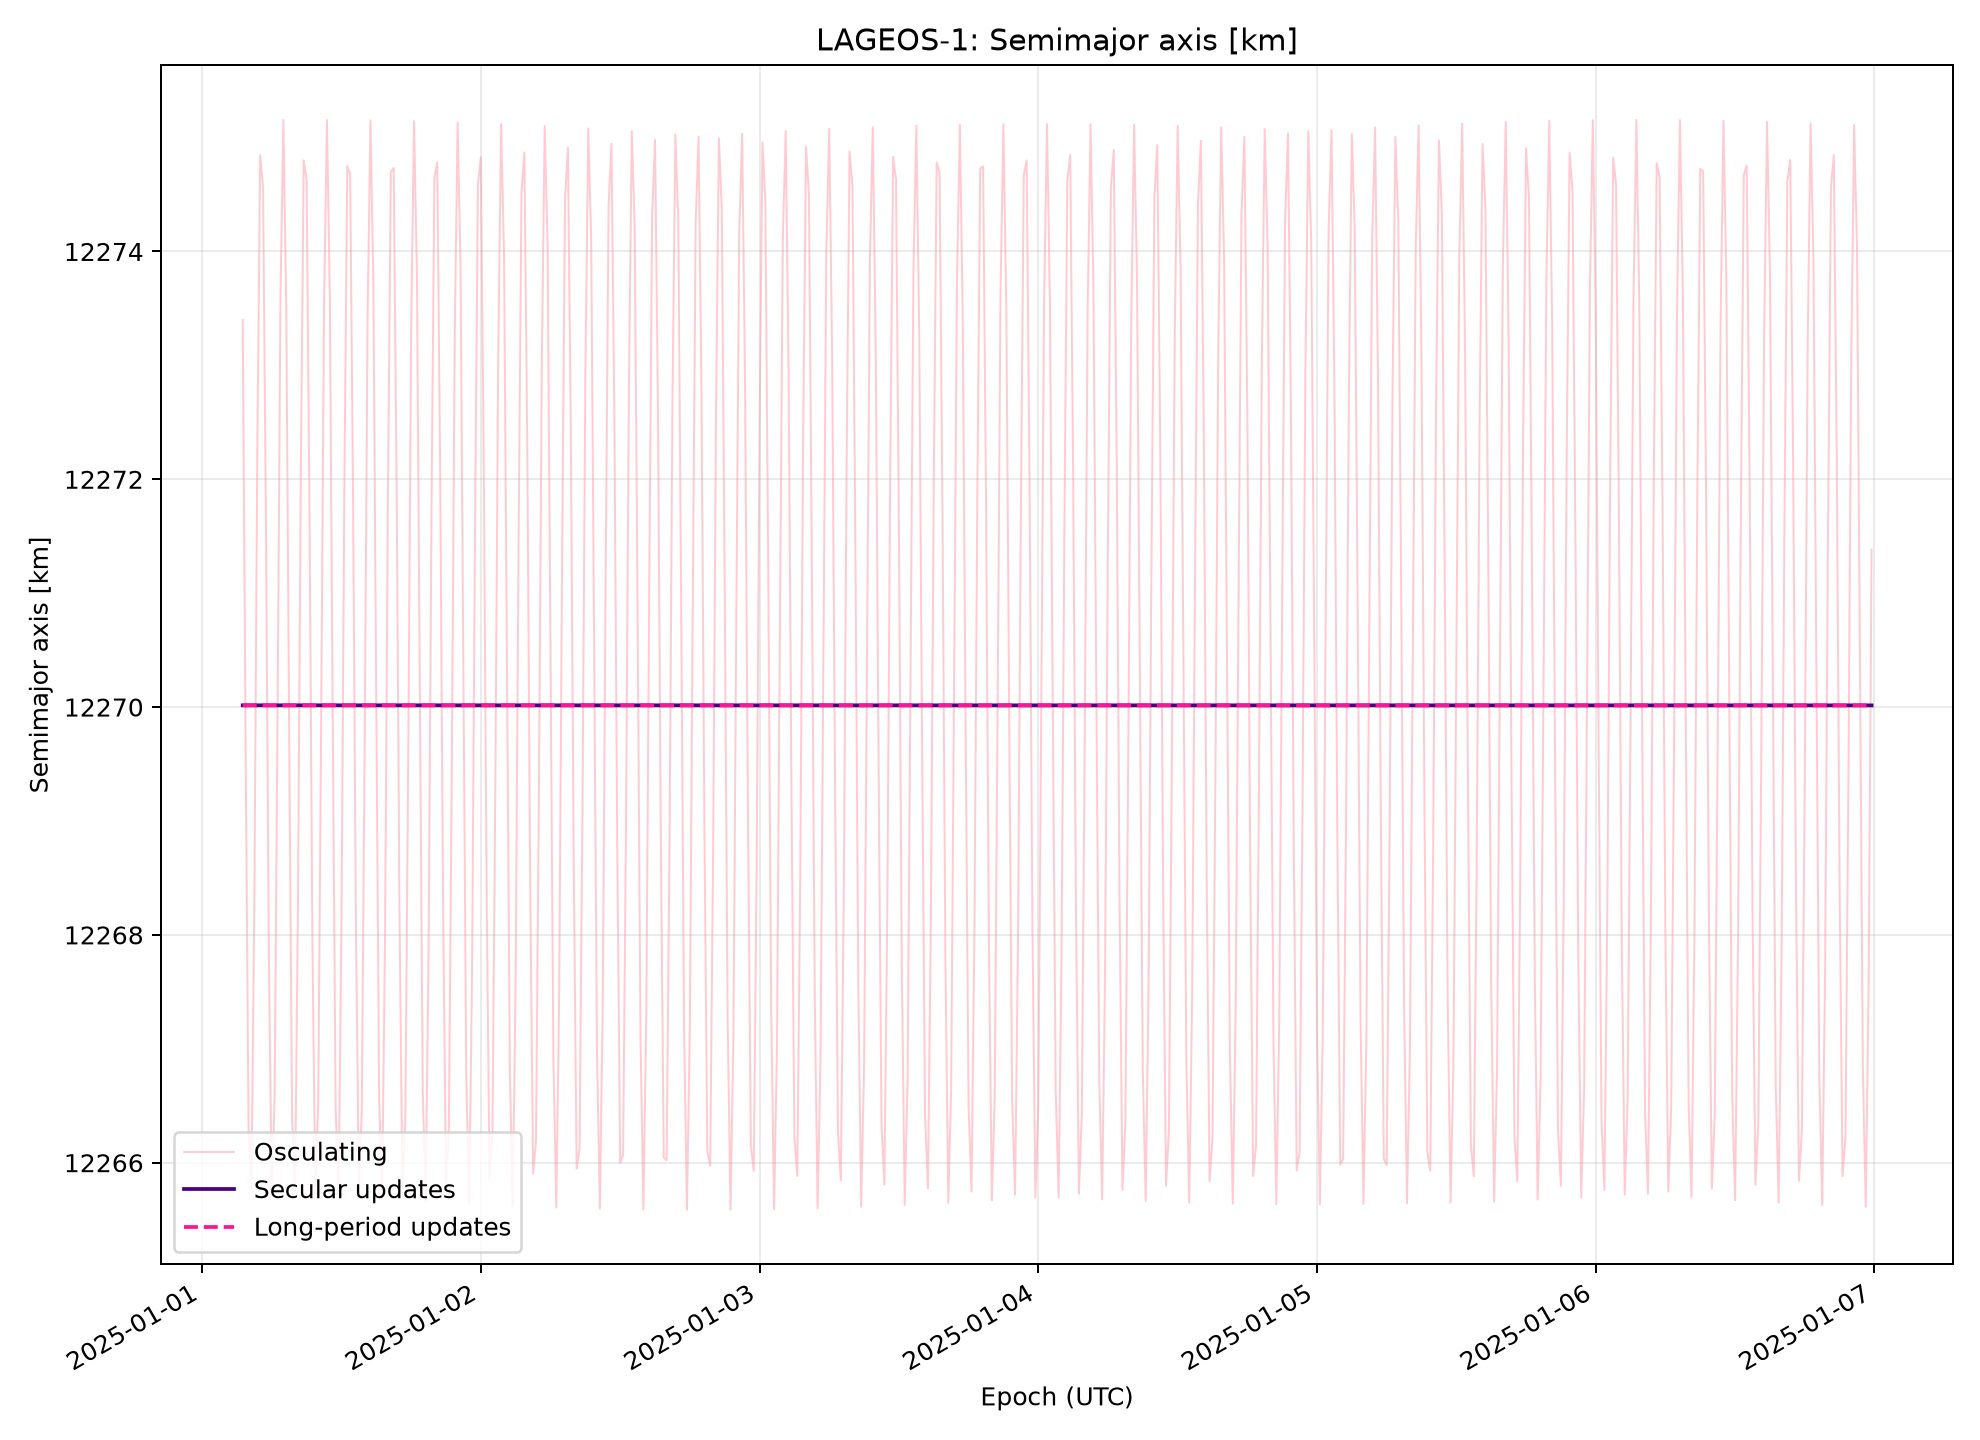

In [29]:
from IPython.display import Image, display
display(Image(filename="figures/a_lageos1.png", width=900))

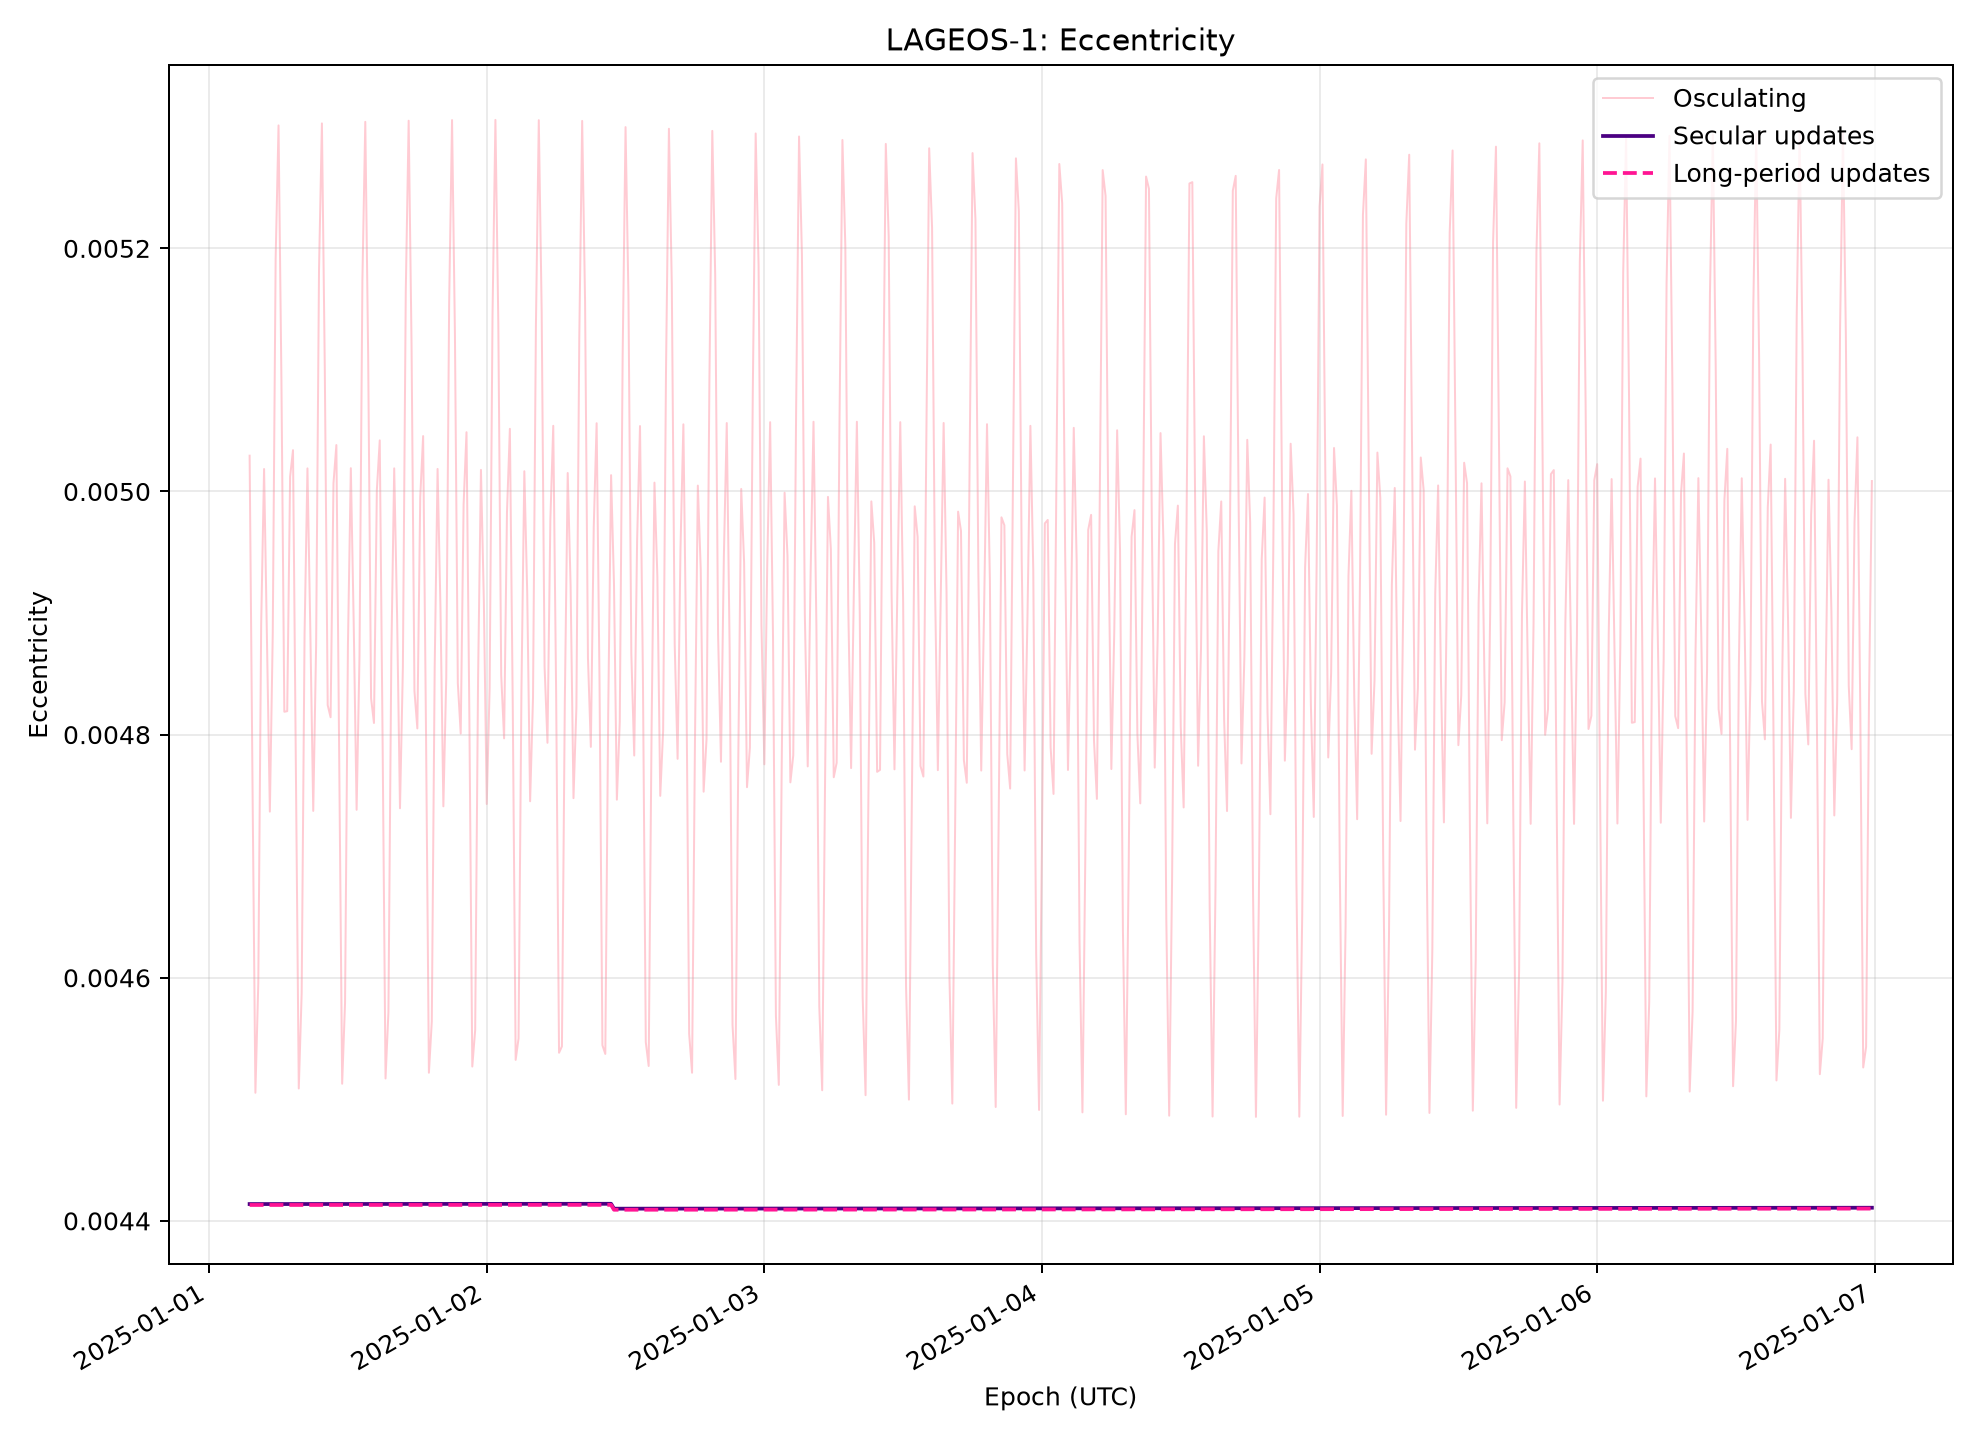

In [30]:
display(Image(filename="figures/e_lageos1.png", width=800))

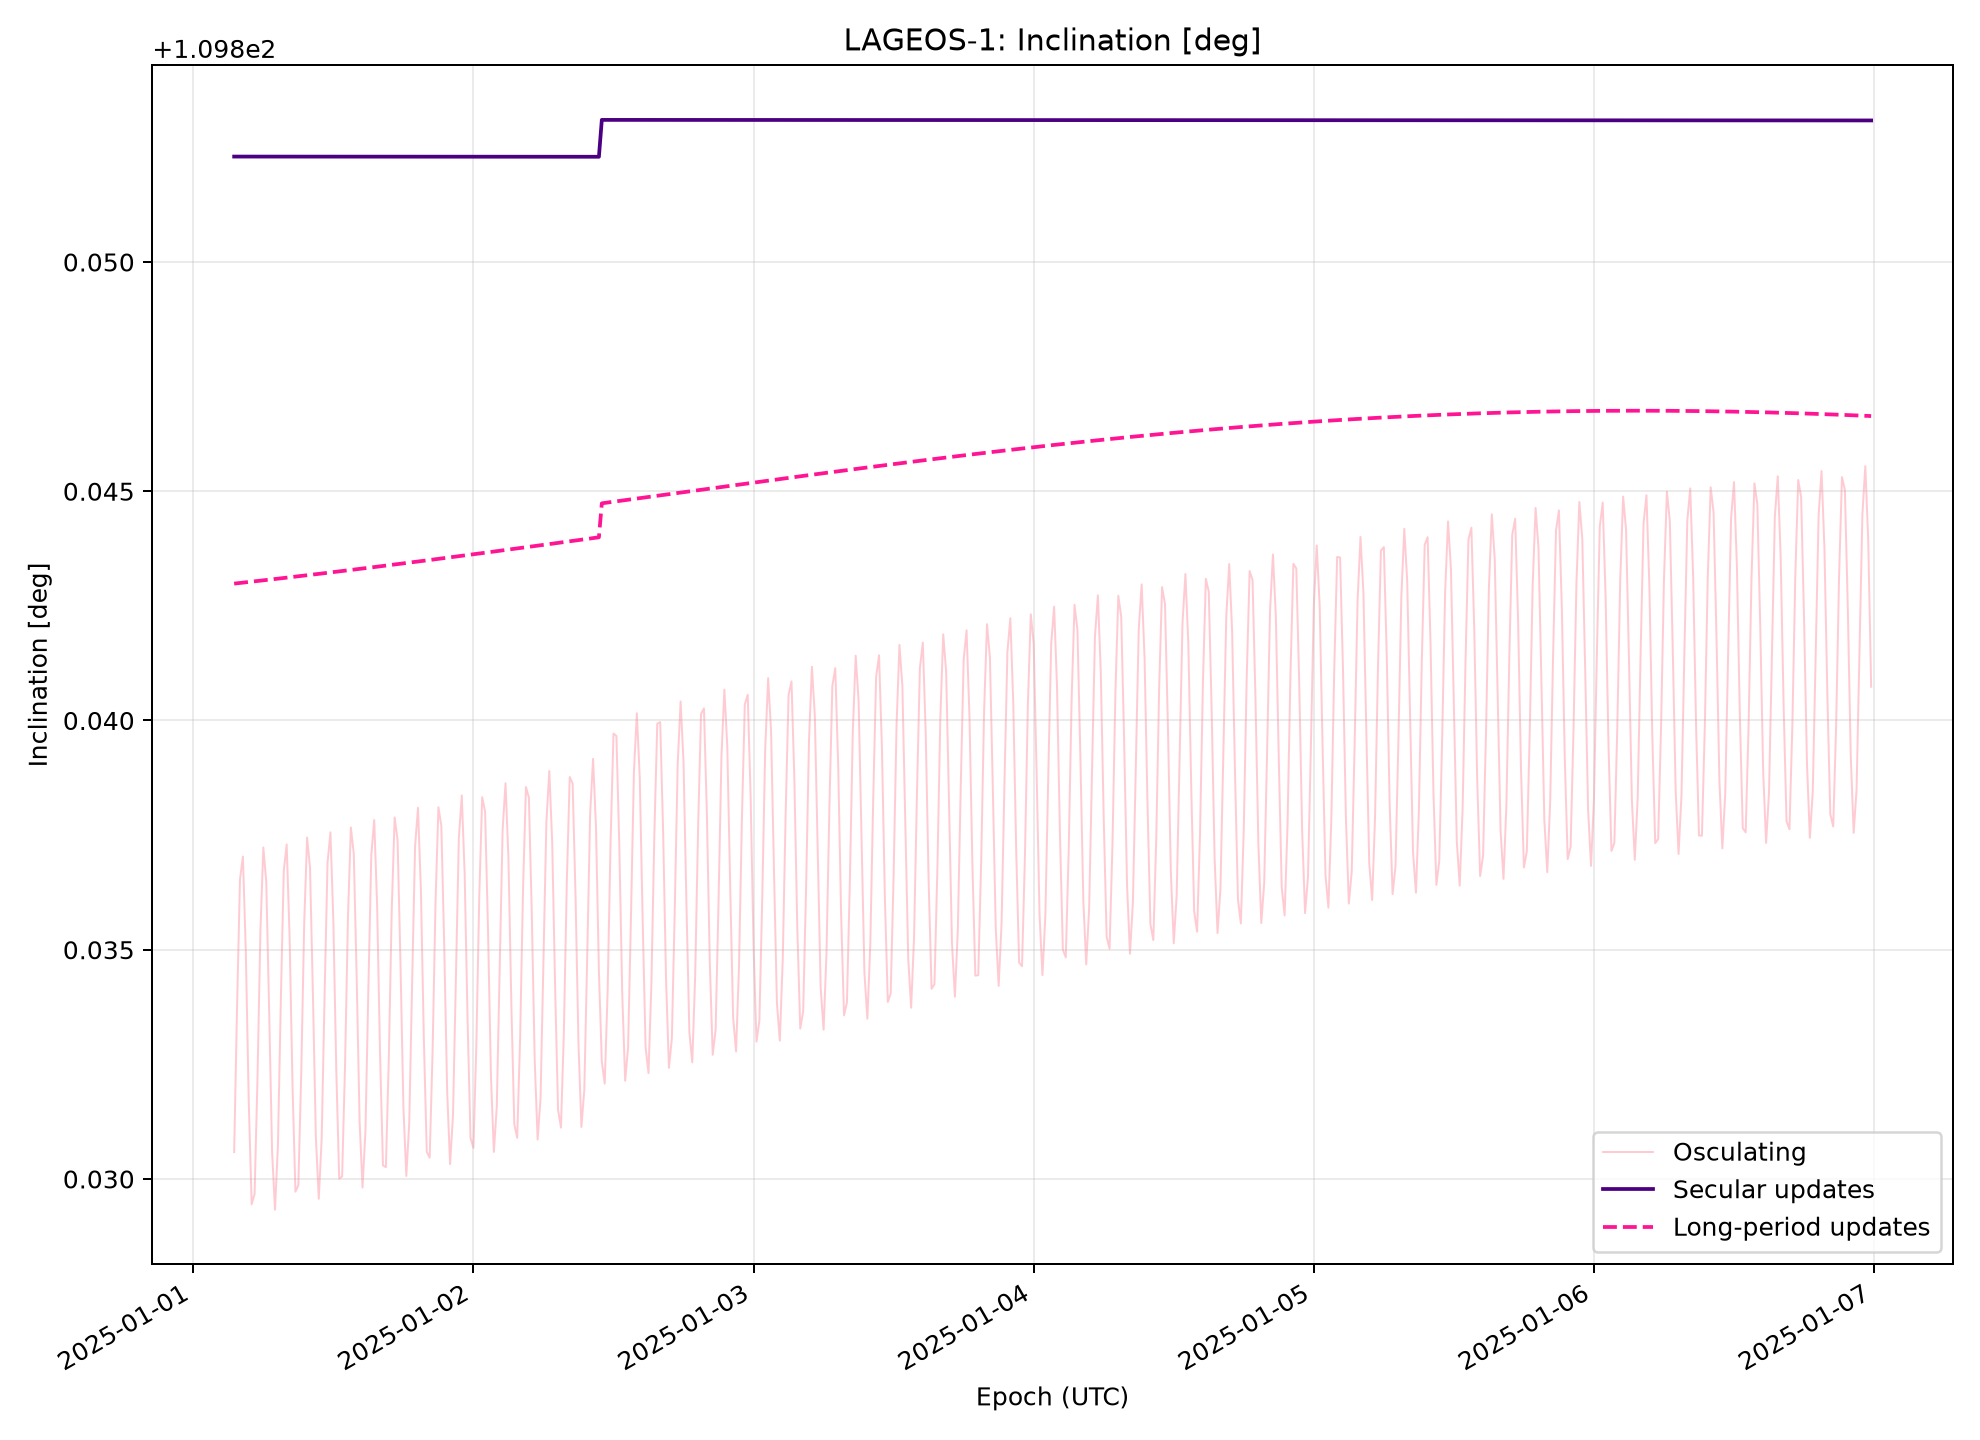

In [31]:
display(Image(filename="figures/i_lageos1.png", width=800))

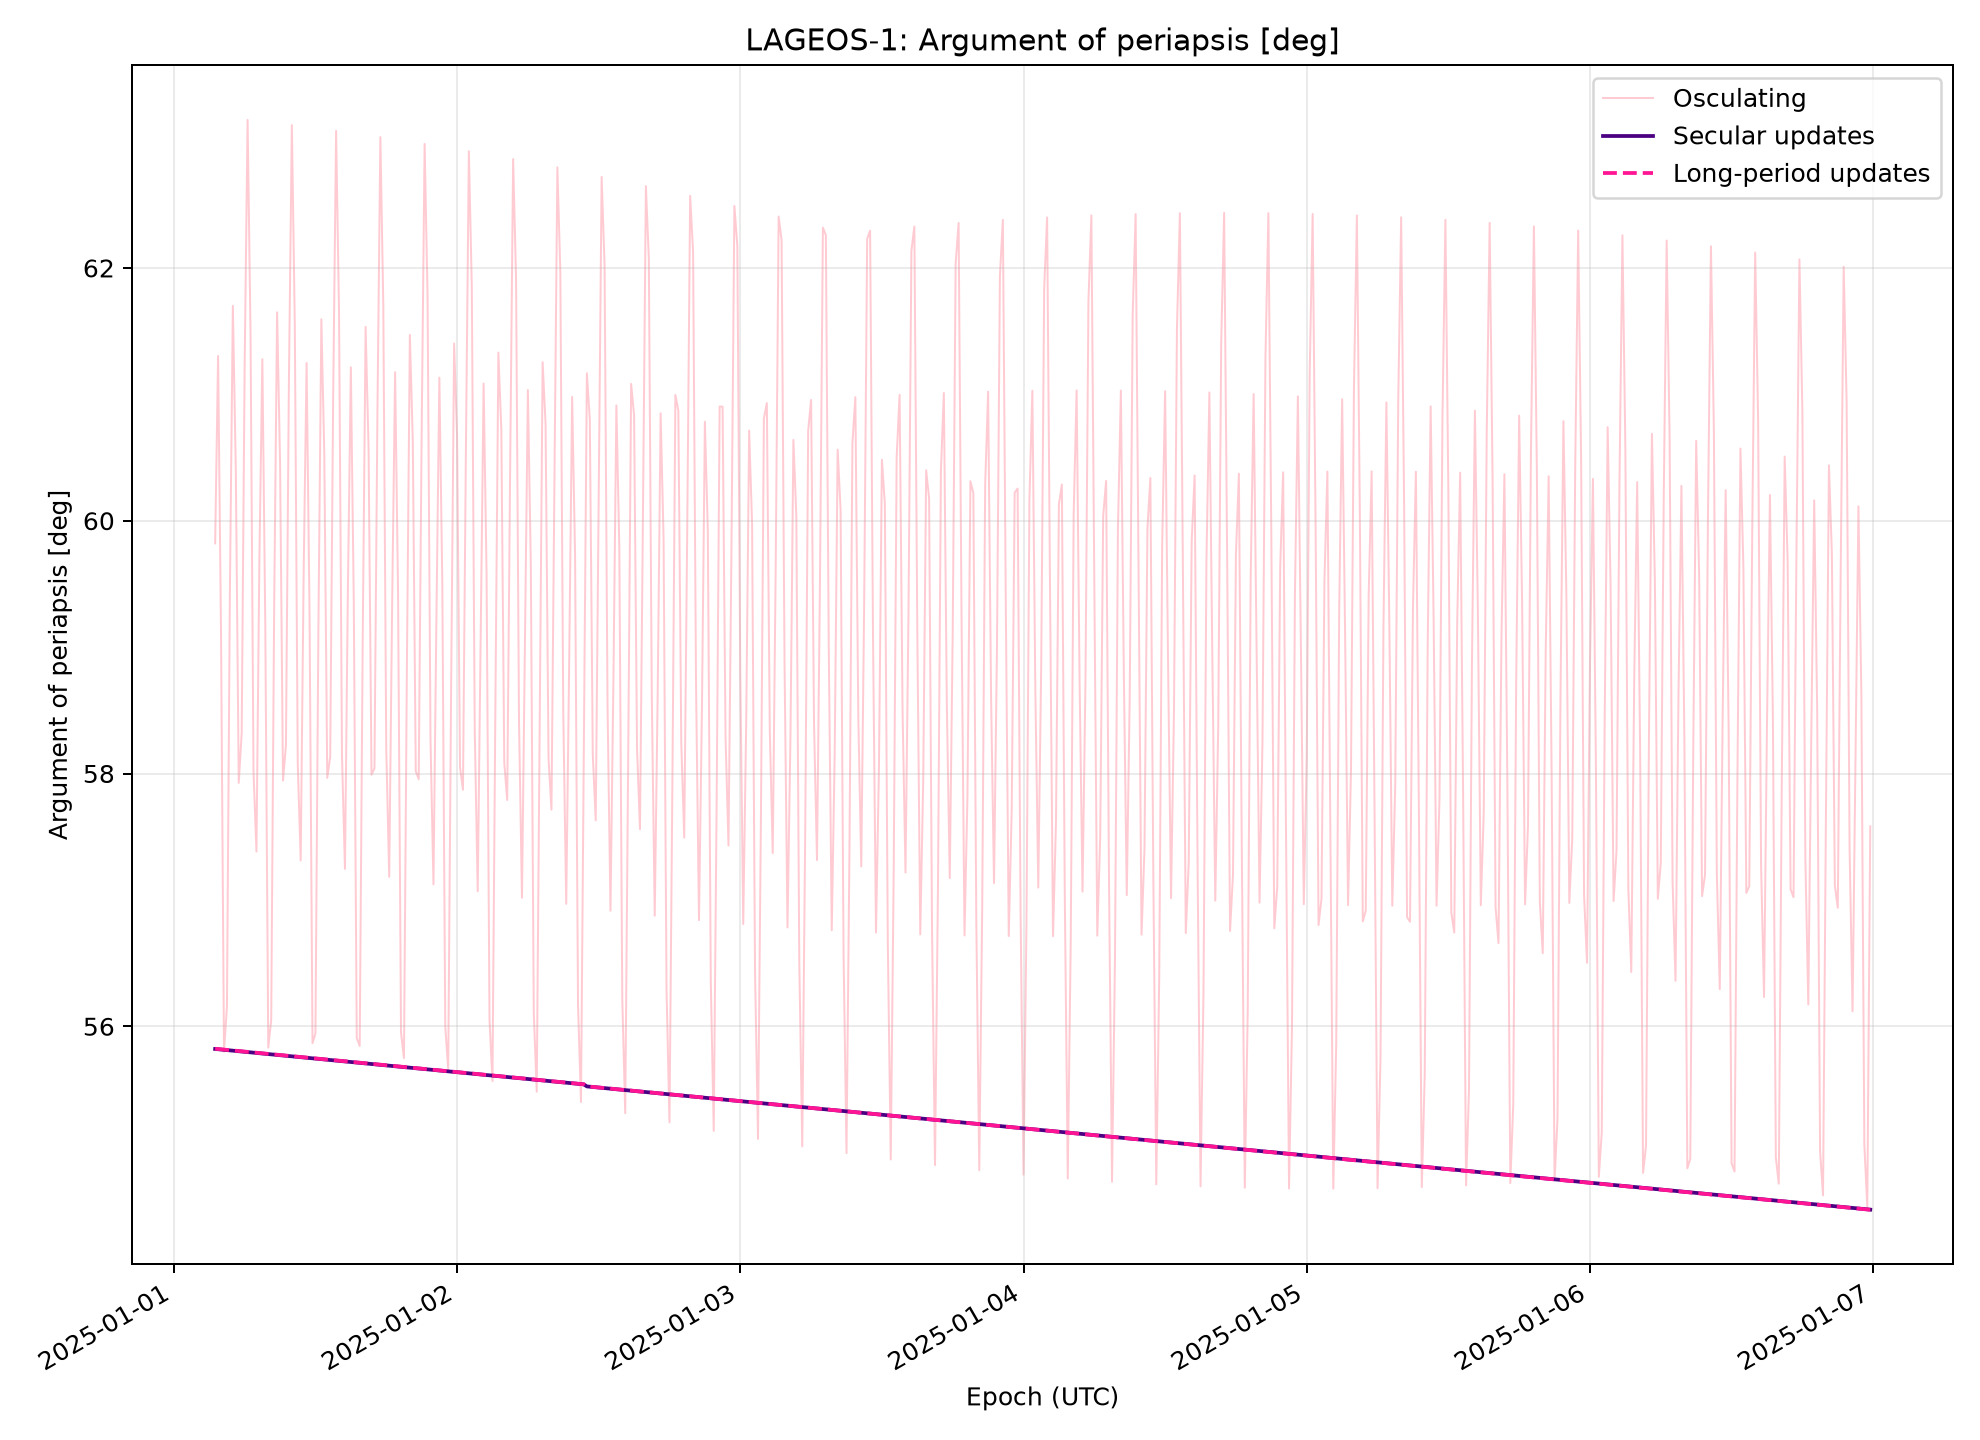

In [32]:
display(Image(filename="figures/omega_lageos1.png", width=800))

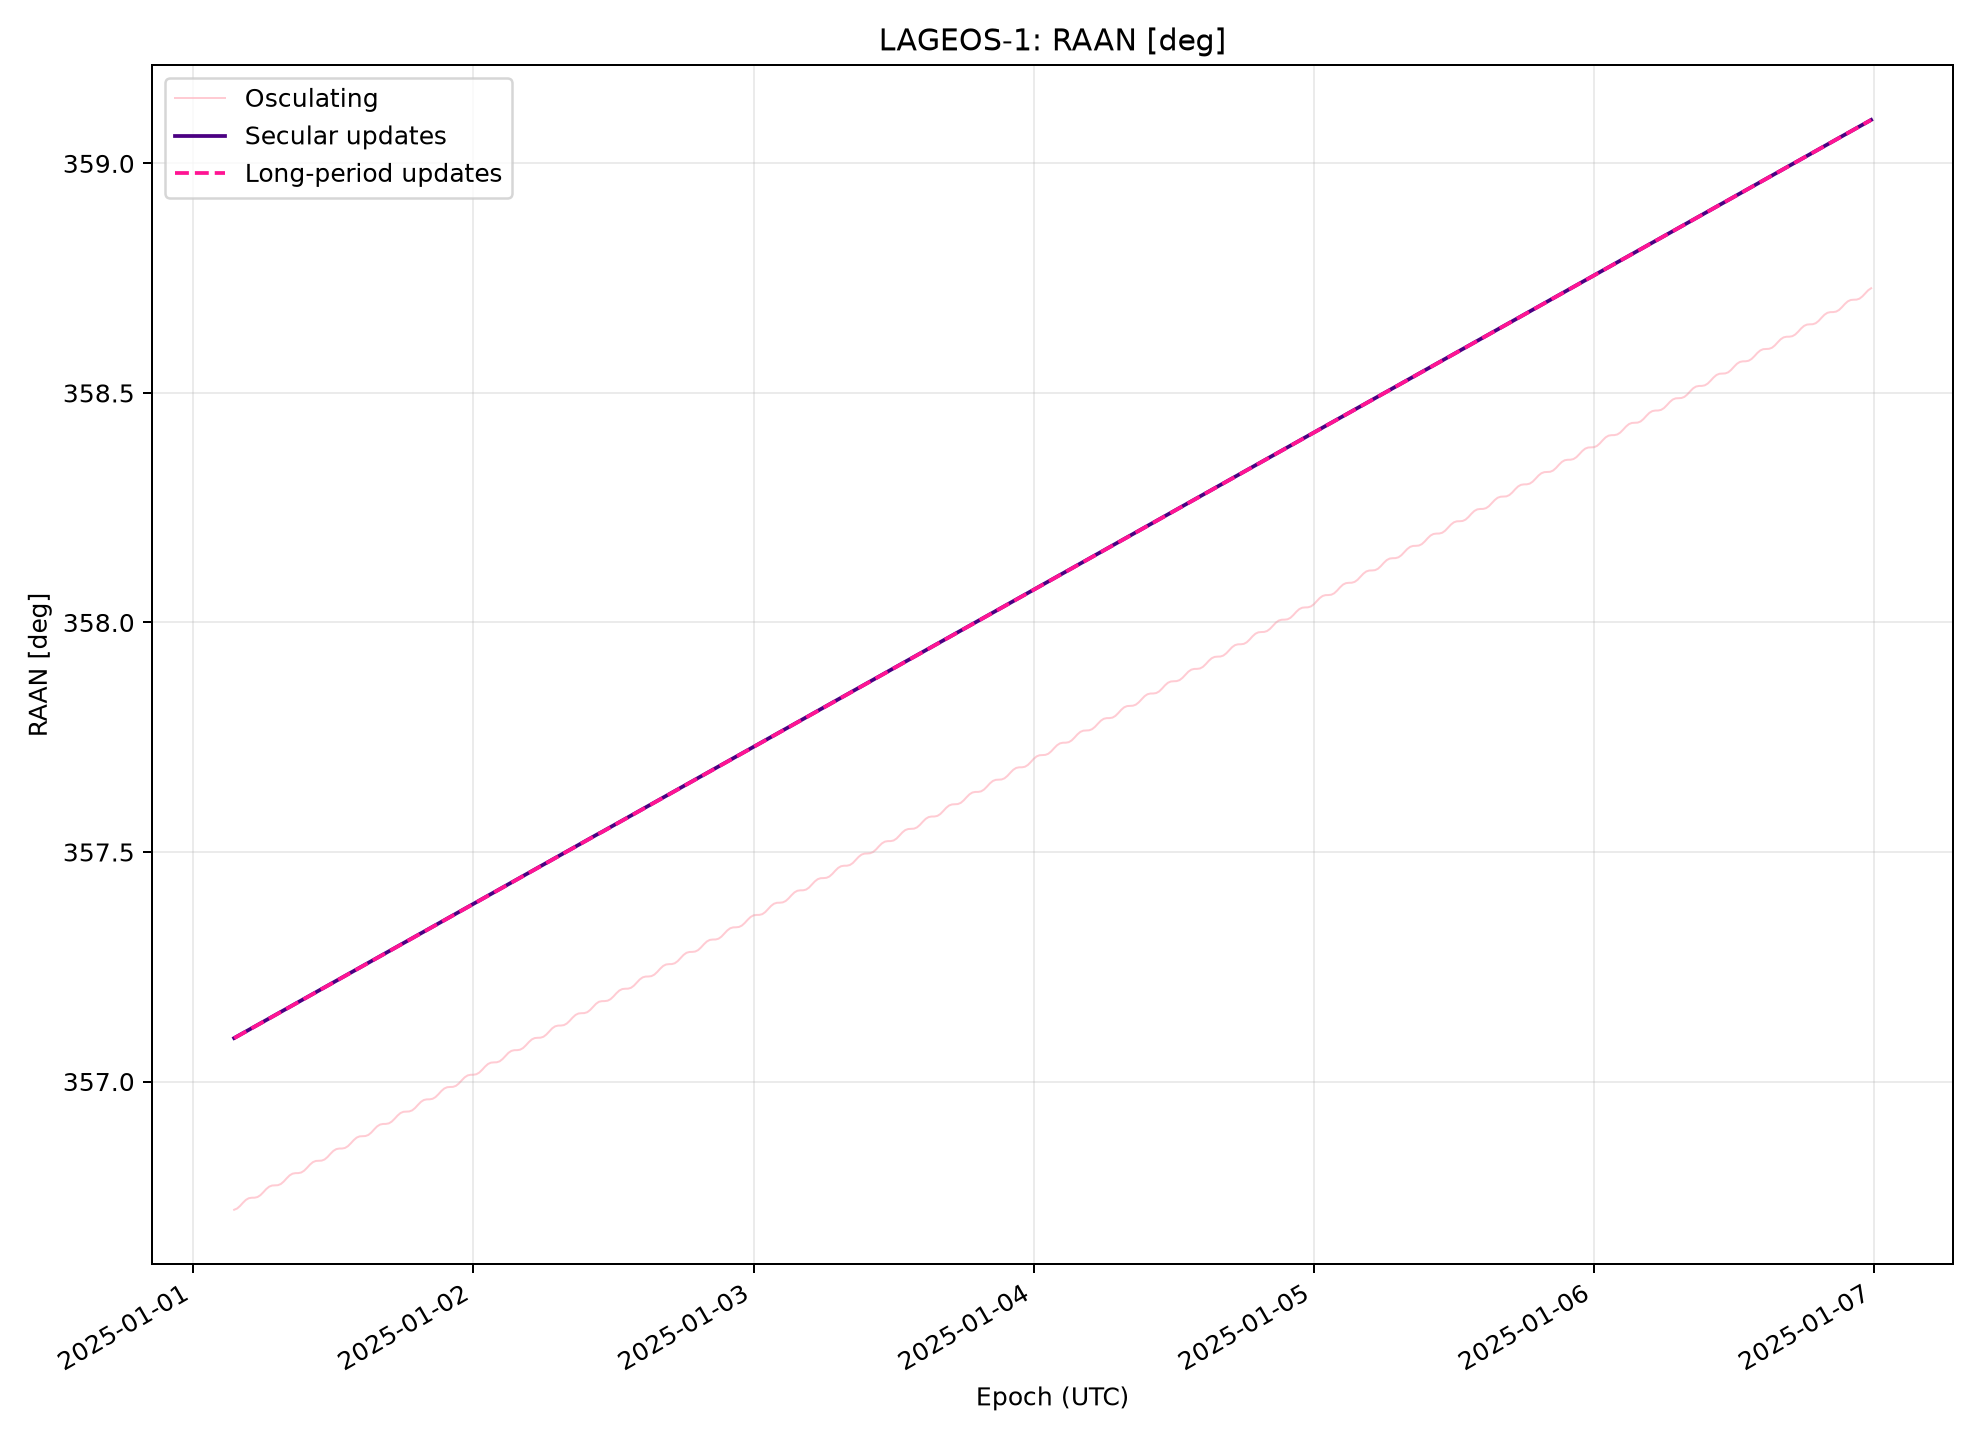

In [33]:
display(Image(filename="figures/raan_lageos1.png", width=800))

### Bibliography

Hoots, F. R., Schumacher Jr., P. W., Glover, R. A. (2004). _History of Analytical Orbit Modeling in the U.S. Space Surveillance System_. Journal of Guidance, Control, and Dynamics, Vol. 27, No. 2.